# Telco Customer Churn - End-to-End Classification Porject

## Project Objectives

The primary objectives of this project are to:

1. Identify factors associated with customer churn: Investigate customer demographics, service subscriptions, contract types, and billing characteristics to understand which factors are associated with customer retention and churn.

2. Demonstrate Exploratory Data Analysis (EDA) skills: Apply statistical techniques and data visualisation to uncover patterns, examine relationships between variables, and translate findings into meaningful business insights.

3. Develop an end-to-end machine learning pipeline: Perform data preprocessing, feature engineering, model training, and evaluation to classify customers based on their likelihood of churning.

## 1. Problem Framing

**Business Context**
Customer churn refers to customers discontinuing their subscription with a service provider. For telecommunications, customer retention is an important business concern, since losing customers can reduce recurring revenue and create additional costs associated with acquiring replacements.

Thus, understanding why customers leave is essential for developing effective retention strategies.

From a predictive modelling perspective, the business implications of correctly and incorrectly identifying customer churn can be summarised as follows:

| Outcome | Prediction | Actual | Business Implication |
|---|---|---|---|
| True Positive (TP) | Churn | Churn | Correctly identifies an at-risk customer, allowing retention efforts. |
| True Negative (TN) | Stay | Stay | Avoids unnecessary retention expenditure. |
| False Positive (FP) | Churn | Stay | Wastes retention resources on customers who would have stayed. |
| False Negative (FN) | Stay | Churn | Missed retention opportunity and potential revenue loss. |

## 2. Exploratory Data Analysis

The purpose of Exploratory Data Analysis (EDA) is to understand the characteristics of the dataset, identify patterns associated with customer churn, and uncover potential relationships between customer attributes and churn behaviour.

Specifically, this analysis aims to:

1. Understand the customer population: Examine the distributions of numerical and categorical variables to understand customer characteristics, subscription plans, and service usage.

2. Investigate churn patterns: Compare customer characteristics between customers who churned and those who remained to identify potential churn indicators.

3. Examine relationships between variables: Use statistical tests and visualisations to assess associations between customer attributes and churn, including the direction and magnitude of observed differences.

4. Identify potential data quality and modelling concerns: Examine missing values, outliers, class imbalance, and relationships between predictors that may affect subsequent modelling.

The findings will help inform feature selection, preprocessing decisions, and the interpretation of predictive models. They will also provide business insights into customer segments that may warrant further investigation or targeted retention strategies.

In [79]:
# Importing the functions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [80]:
# Reading the Dataset
root = Path.cwd().parent
df = pd.read_csv(root / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [81]:
# Check Datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Upon initial inspection, several variables are stored in data types that do not accurately reflect their underlying characteristics.

1. `TotalCharges` is stored as a string (object) despite representing numerical values. It should be converted to a numeric data type to enable numerical analysis.

2. `SeniorCitizen` is stored as an integer (int), although it represents a binary categorical variable (0 = No, 1 = Yes). Converting it to a boolean or categorical data type would better reflect its meaning.

3. Other categorical variables are stored as strings (object). Converting these to the category data type can improve data consistency, reduce memory usage, and facilitate categorical analysis.

Therefore, these variables will be converted to their appropriate data types to ensure accurate interpretation and subsequent analysis.

### 2.1 Adjust data types

In [82]:
# Change TotalCharges data type of float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# List down the data where we will change their data types to category
binary_cols = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "SeniorCitizen"
]

for col in binary_cols:
    df[col] = df[col].astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   category
 2   SeniorCitizen     7043 non-null   category
 3   Partner           7043 non-null   category
 4   Dependents        7043 non-null   category
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   category
 7   MultipleLines     7043 non-null   str     
 8   InternetService   7043 non-null   str     
 9   OnlineSecurity    7043 non-null   str     
 10  OnlineBackup      7043 non-null   str     
 11  DeviceProtection  7043 non-null   str     
 12  TechSupport       7043 non-null   str     
 13  StreamingTV       7043 non-null   str     
 14  StreamingMovies   7043 non-null   str     
 15  Contract          7043 non-null   str     
 16  PaperlessBilling  7043 non-null   s

In [83]:
df.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [84]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"Duplicate rows: {df.duplicated().sum()}")

TotalCharges    11
dtype: int64
Duplicate rows: 0


In [85]:
df[df['TotalCharges'].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Upon inspection, `TotalCharges` contains 11 missing values, representing approximately 0.16% of the dataset.

Given the small proportion of missing observations, these rows were removed rather than imputed to avoid introducing potentially inaccurate values. This results in a final dataset of 7,032 observations, with minimal loss of information.

In [86]:
df_copy = df.dropna(subset=["TotalCharges"]).copy()
print(df_copy.isnull().sum()[df_copy.isnull().sum() > 0])

Series([], dtype: int64)


### 2.2 Target Class Check

In [88]:
df_copy["Churn"].value_counts(normalize=True).round(4)

Churn
No     0.7342
Yes    0.2658
Name: proportion, dtype: float64

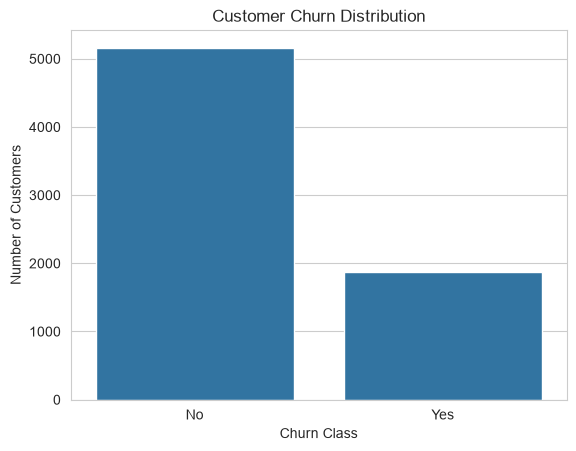

In [89]:
sns.countplot(data=df_copy, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Class")
plt.ylabel("Number of Customers")
plt.show()

The dataset shows that approximately 73% of customers stayed, while 27% churned, indicating a moderate class imbalance.

As a result, accuracy alone may be misleading, since a model could achieve approximately 73% accuracy by predicting that every customer will stay.

To address this during data splitting, we will use `stratified sampling` to preserve the original class proportions in both the training and testing sets. This ensures that both sets have a representative distribution of churned and non-churned customers.

For model evaluation, we will prioritise `precision`, `recall`, and `F1-score`, rather than relying solely on accuracy.

### 2.3 Numerical Feature Distributions

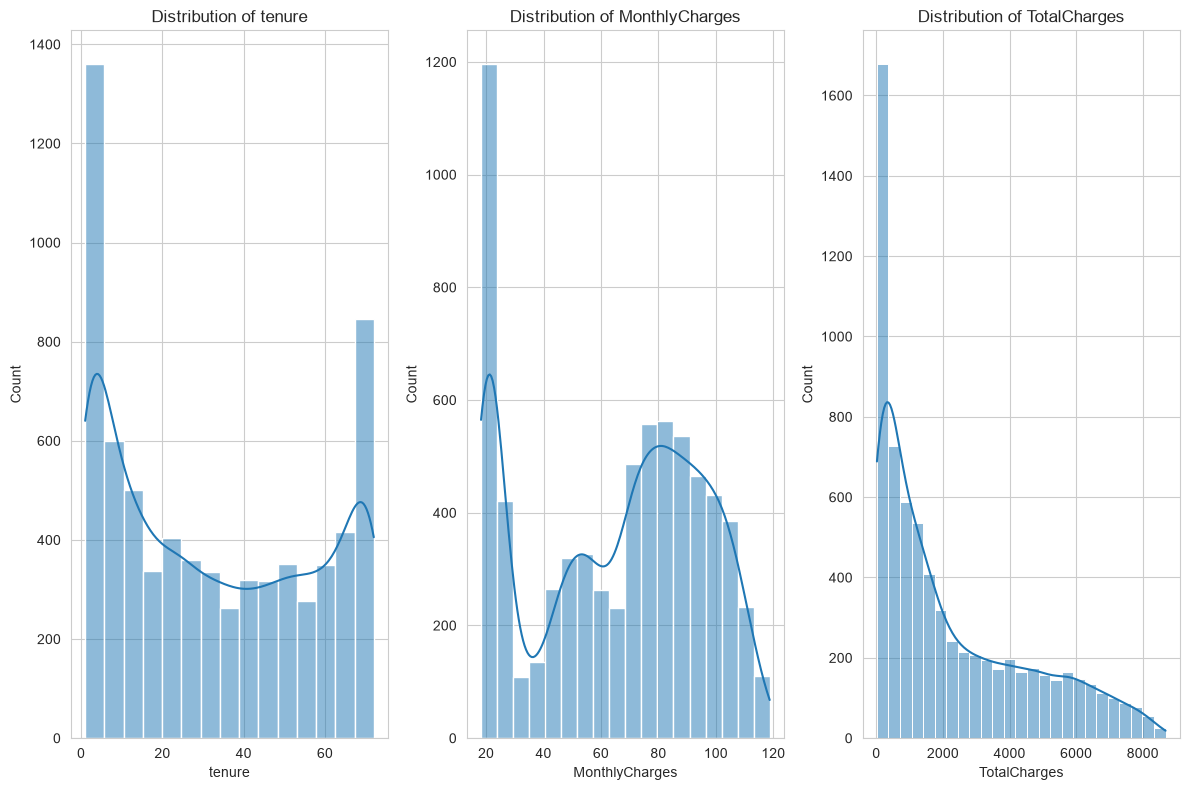

In [90]:
numeric_cols = df_copy.select_dtypes(include=["int64", "float64"]).columns.tolist()

fig, axes = plt.subplots(1, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df_copy[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
fig.tight_layout()
plt.show()

`tenure` is roughly bimodal (a large group of very new customers and another of long-tenured ones). `MonthlyCharges` is bimodal too, reflecting distinct pricing tiers. `TotalCharges` is right-skewed, which follows naturally from `TotalCharges` ≈ `tenure` × `MonthlyCharges`.

### 2.4 Categorical feature checks

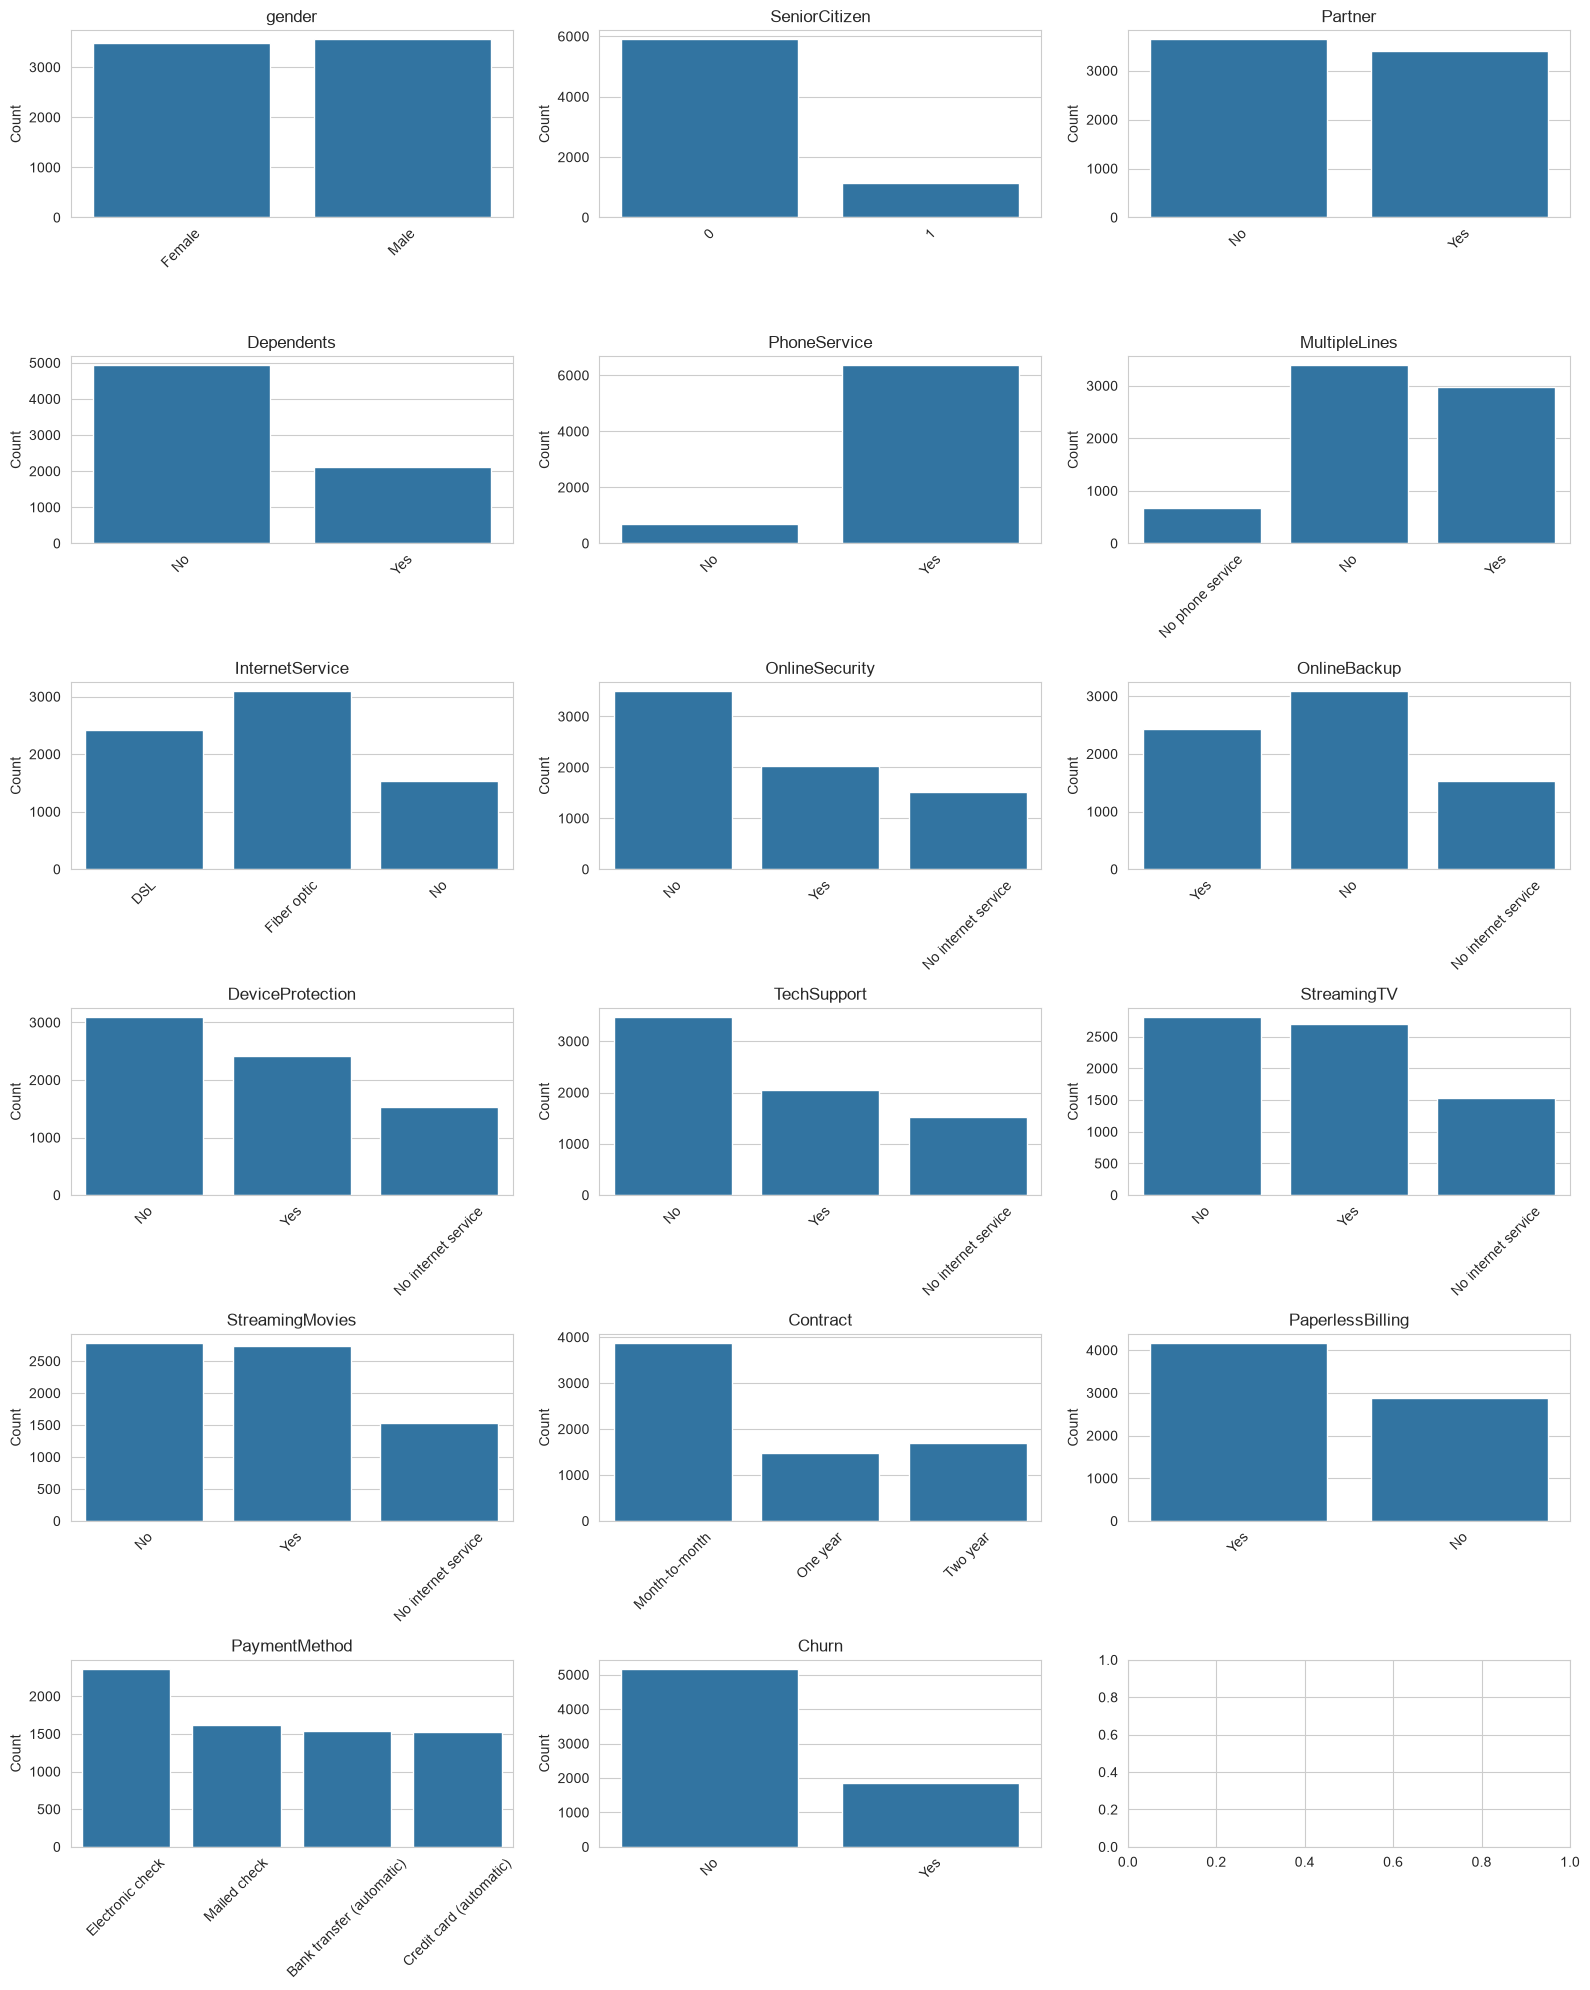

In [91]:
cat_cols = df.select_dtypes(include=["category", "str"]).columns.tolist()
cat_cols.remove("customerID")
fig, axes = plt.subplots(6, 3, figsize=(16, 20))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

### 2.5 Correlation of numeric features with churn

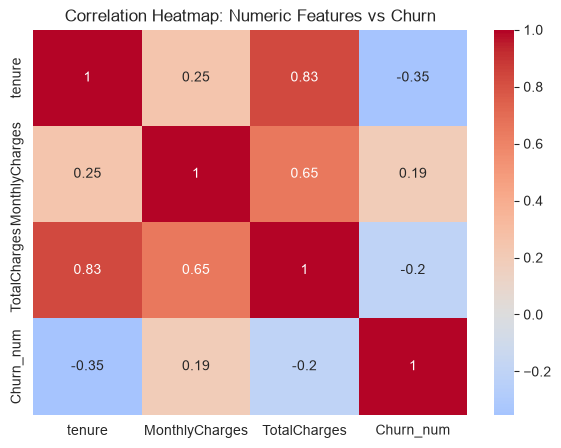

Churn_num         1.000000
MonthlyCharges    0.193356
TotalCharges     -0.199484
tenure           -0.352229
Name: Churn_num, dtype: float64

In [92]:
df_corr = df.copy()
df_corr["Churn_num"] = df_corr["Churn"].map({"Yes": 1, "No": 0})

corr = df_corr[numeric_cols + ["Churn_num"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: Numeric Features vs Churn")
plt.show()

corr["Churn_num"].sort_values(ascending=False)

The correlation analysis indicates that `tenure` has the strongest relationship with customer churn among the numerical variables examined (r = -0.352). This suggests that customers with longer `tenure` tend to be less likely to churn.

`MonthlyCharges` shows a weak positive correlation (r = 0.193), indicating that customers with higher monthly charges may be somewhat more likely to churn.

Interestingly, `TotalCharges` has a weak negative correlation (r = -0.199). This may be explained by its relationship with `tenure`, as longer-standing customers generally accumulate higher total charges.

Overall, `tenure` appears to be a more informative indicator of churn than monthly or total charges when these variables are examined individually. However, correlation alone does not establish causality or determine their predictive importance in a machine learning model.

### 2.6 Chi-square test: categorical features vs churn

The chi-square test of independence checks whether a categorical feature and the target are statistically associated. A p-value below 0.05 means the association is unlikely to be due to chance.

Our hypotheses are:
- H₀: The feature and customer churn are independent.
- H₁: The feature and customer churn are associated.

In [93]:
p_values = {}
for col in cat_cols:
    contingency_table = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, expected = chi2_contingency(contingency_table, correction=True)
    p_values[col] = p

print("Features ranked by association with churn (ascending p-value):\n")
for col, p in sorted(p_values.items(), key=lambda x: x[1]):
    flag = "significant (p < 0.05)" if p < 0.05 else "not significant"
    print(f"  {col:<20} p = {p:.6f}   {flag}")

Features ranked by association with churn (ascending p-value):

  Churn                p = 0.000000   significant (p < 0.05)
  Contract             p = 0.000000   significant (p < 0.05)
  OnlineSecurity       p = 0.000000   significant (p < 0.05)
  TechSupport          p = 0.000000   significant (p < 0.05)
  InternetService      p = 0.000000   significant (p < 0.05)
  PaymentMethod        p = 0.000000   significant (p < 0.05)
  OnlineBackup         p = 0.000000   significant (p < 0.05)
  DeviceProtection     p = 0.000000   significant (p < 0.05)
  StreamingMovies      p = 0.000000   significant (p < 0.05)
  StreamingTV          p = 0.000000   significant (p < 0.05)
  PaperlessBilling     p = 0.000000   significant (p < 0.05)
  Dependents           p = 0.000000   significant (p < 0.05)
  SeniorCitizen        p = 0.000000   significant (p < 0.05)
  Partner              p = 0.000000   significant (p < 0.05)
  MultipleLines        p = 0.003464   significant (p < 0.05)
  PhoneService       

Most categorical variables, including Contract, OnlineSecurity, TechSupport, InternetService, and PaymentMethod, showed statistically significant associations with churn (p < 0.05).

In contrast, `PhoneService` (p = 0.339) and `gender` (p = 0.487) did not show statistically significant associations at the 5% significance level.

These findings suggest that service subscriptions, contract arrangements, and payment methods may be relevant to understanding customer churn.

However, statistical significance does not indicate the strength or direction of a relationship. Further analysis of churn rates across categories is necessary.

### 2.7 Numeric features vs churn class (boxplots)

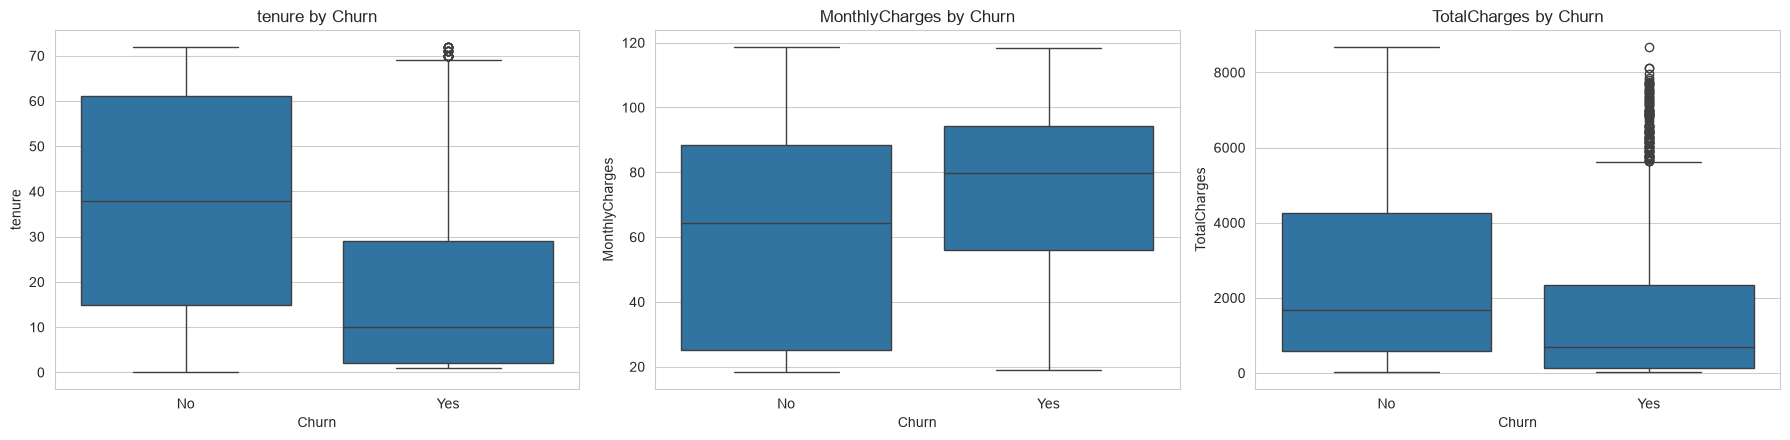

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} by Churn")
fig.tight_layout()
plt.show()

`tenure` shows the clearest separation — churners are concentrated at low `tenure`. `MonthlyCharges` is visibly higher for churners. `TotalCharges` separates less cleanly on its own, again because it's a product of the other two.

### 2.8 Outlier handling

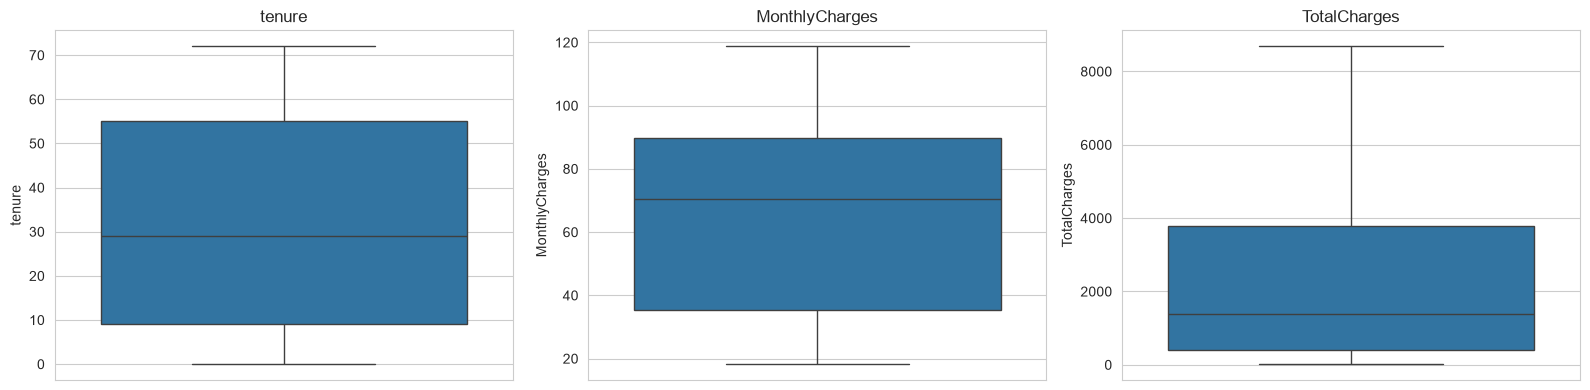

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
fig.tight_layout()
plt.show()

Boxplots were used to examine potential outliers in `tenure`, `MonthlyCharges`, and `TotalCharges`.

No observations were identified beyond the standard boxplot whiskers, suggesting that there are no obvious outliers based on the 1.5 × IQR criterion.

`TotalCharges` exhibits a positively skewed distribution, while `MonthlyCharges` appears relatively balanced in its boxplot despite the previously observed bimodal pattern.

**Decision:** Based on these findings, no outlier removal is necessary at this stage. We will retain the numerical observations for modelling.

### 2.9 Multicollinearity Check

In [96]:
numeric_cols_vif = ["tenure", "MonthlyCharges", "TotalCharges"]
vif_data = df[numeric_cols_vif].dropna()

vif_df = pd.DataFrame()
vif_df["Feature"] = vif_data.columns
vif_df["VIF"] = [
    variance_inflation_factor(vif_data.values, i) for i in range(vif_data.shape[1])
]
vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
2,TotalCharges,9.526697
0,tenure,5.844646
1,MonthlyCharges,3.225293


The correlation heatmap reveals that `TotalCharges` exhibits strong positive correlations with both `tenure` and `MonthlyCharges`, suggesting that these variables contain overlapping information.

This finding is further supported by the Variance Inflation Factor (VIF) analysis, where `TotalCharges` has a relatively high VIF of approximately 9.53, indicating substantial multicollinearity with the other numerical predictors.

This relationship is understandable because `TotalCharges` represents cumulative customer expenditure, which is closely related to subscription duration and monthly billing amounts.

Since multicollinearity can affect the stability and interpretability of regression coefficients, `TotalCharges` will be considered for exclusion from the logistic regression model. Retaining `tenure` and `MonthlyCharges` allows the model to capture subscription duration and recurring costs separately.

In [97]:
numeric_cols_vif = ["tenure", "MonthlyCharges"]
vif_data = df[numeric_cols_vif].dropna()

vif_df = pd.DataFrame()
vif_df["Feature"] = vif_data.columns
vif_df["VIF"] = [
    variance_inflation_factor(vif_data.values, i) for i in range(vif_data.shape[1])
]
vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
1,MonthlyCharges,1.065478
0,tenure,1.065478


In [ ]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_copy.to_csv(output_dir / "telco_churn_cleaned.csv", index=False)